=== T_LOG v15.1 | MODE = ROBUST ===
  Realisations : 5 | Steps : 40000 | Test : cliff_delta | Algo : auto

Points T : 28 | Tc = 2.2692

>>> L = 32

[Build L=32] 5 realisation(s), 40000 steps, mode robust


L=32 ensemble: 100%|██████████| 5/5 [32:53<00:00, 394.63s/it]


Features : 30
      T  M_Higuchi_mean  M_DFA_mean  M_Katz_mean  M_CorrDim_mean
0  1.50        2.058362    1.990782     7.234987             NaN
1  1.56        2.057400    1.990086     7.362220             NaN
2  1.62        2.055186    1.989565     6.915700             NaN


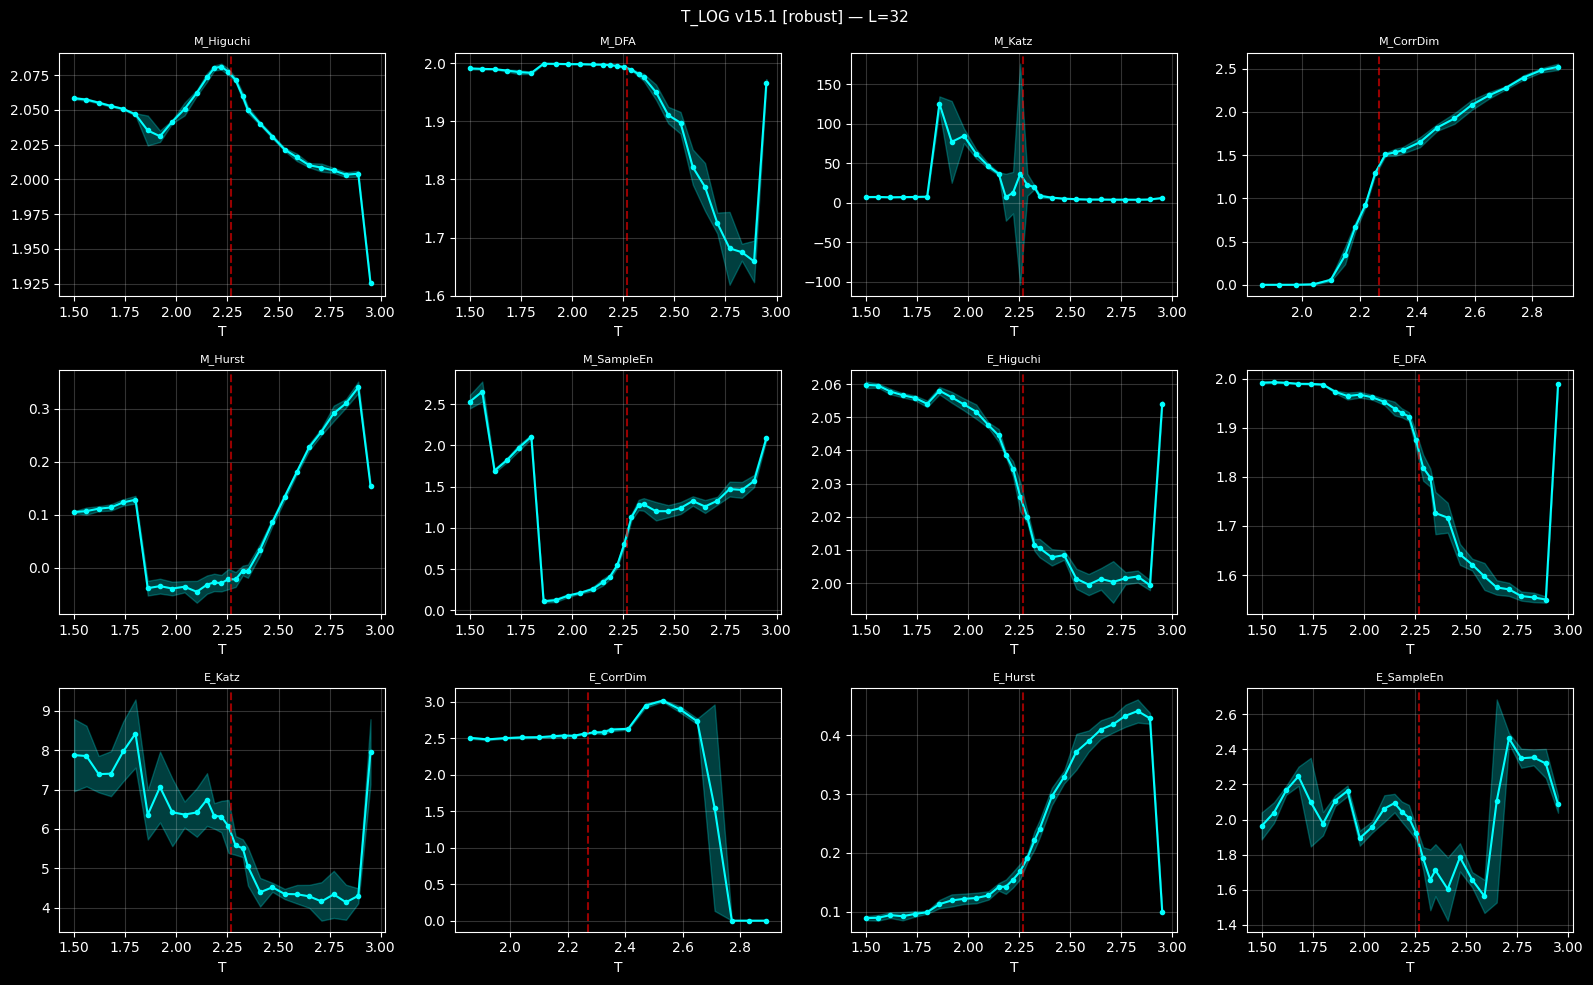


=== 4 Questions ===
Q1: Ordre vs Desordre...
Q2: Tension critique...
Q3: Apathie vs Dynamisme...
Q4: Symetrie spontanee...

>>> RESULTATS L=32:
                        Q1_Ordre_vs_Desordre  Q2_Tension_critique  Q3_Apathie_vs_Dynamisme  Q4_Symetrie_spontanee
Cluster_CorrDim_mean                   0.303                 0.36                    0.240                  0.019
Cluster_DFA_mean                       0.076                 1.00                    0.008                  0.019
Cluster_Higuchi_mean                   0.121                 0.12                    0.190                  0.019
Cluster_Hurst_mean                     0.970                 1.00                    0.967                  0.019
Cluster_Katz_mean                      0.182                 0.20                    0.273                  0.019
Cluster_SampleEn_mean                  0.348                 1.00                    0.289                  0.019
E_CorrDim_mean                         0.200             

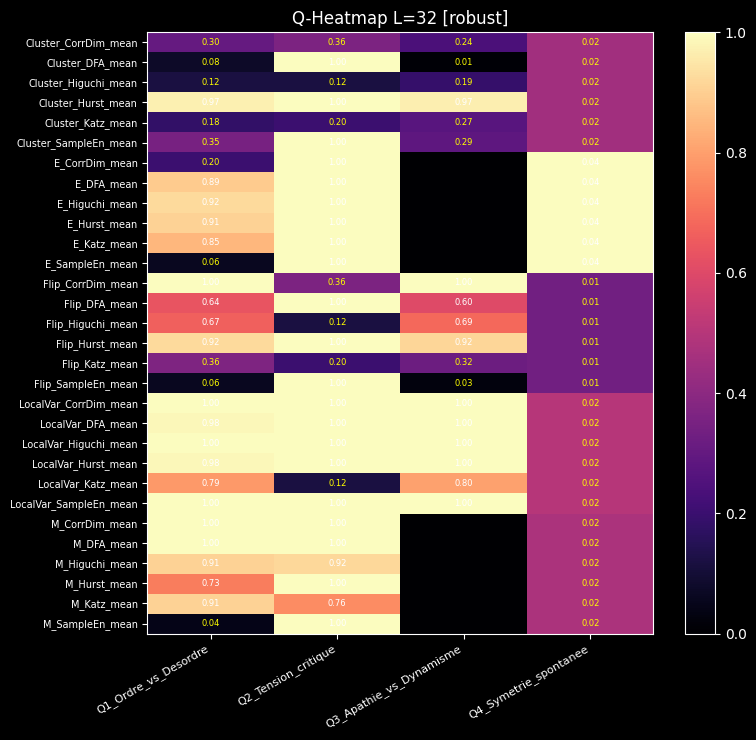


>>> L = 48

[Build L=48] 5 realisation(s), 40000 steps, mode robust


L=48 ensemble: 100%|██████████| 5/5 [1:04:52<00:00, 778.46s/it]


Features : 30
      T  M_Higuchi_mean  M_DFA_mean  M_Katz_mean  M_CorrDim_mean
0  1.50        2.058776    1.990315     6.857127             NaN
1  1.56        2.057492    1.991145     7.293703             NaN
2  1.62        2.055436    1.989626     7.336115             NaN


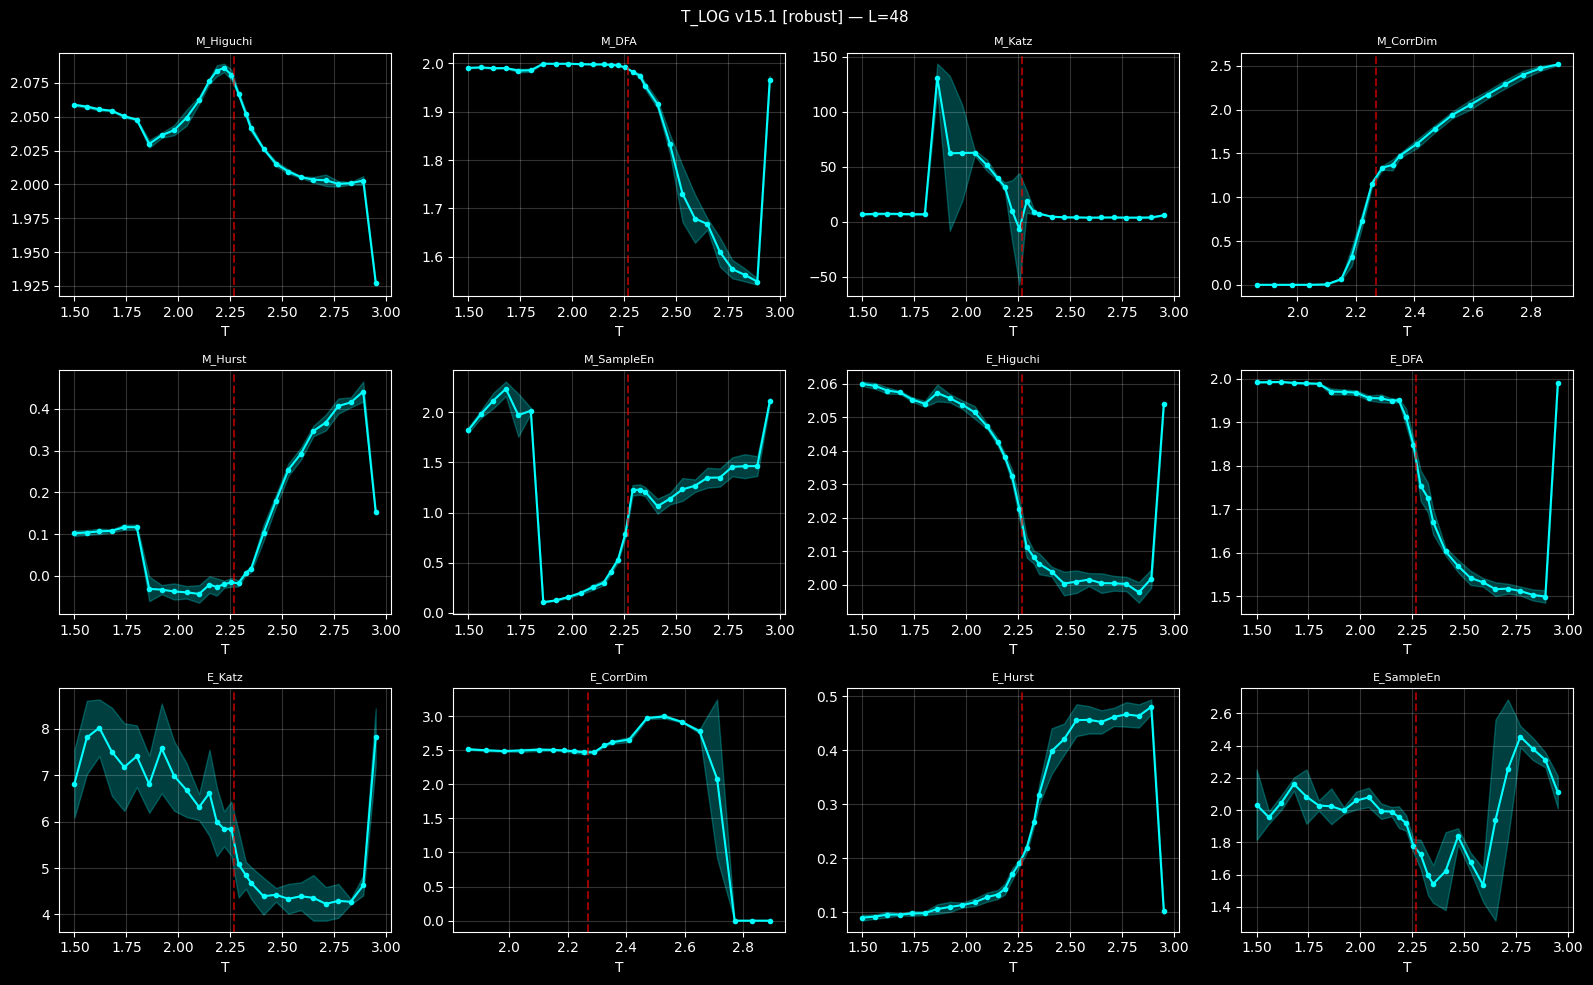


=== 4 Questions ===
Q1: Ordre vs Desordre...
Q2: Tension critique...
Q3: Apathie vs Dynamisme...
Q4: Symetrie spontanee...

>>> RESULTATS L=48:
                        Q1_Ordre_vs_Desordre  Q2_Tension_critique  Q3_Apathie_vs_Dynamisme  Q4_Symetrie_spontanee
Cluster_CorrDim_mean                   0.121                 0.84                    0.041                  0.027
Cluster_DFA_mean                       0.167                 1.00                    0.273                  0.027
Cluster_Higuchi_mean                   0.242                 0.20                    0.190                  0.027
Cluster_Hurst_mean                     0.985                 1.00                    1.000                  0.027
Cluster_Katz_mean                      0.091                 0.60                    0.190                  0.027
Cluster_SampleEn_mean                  0.439                 1.00                    0.388                  0.027
E_CorrDim_mean                         0.200             

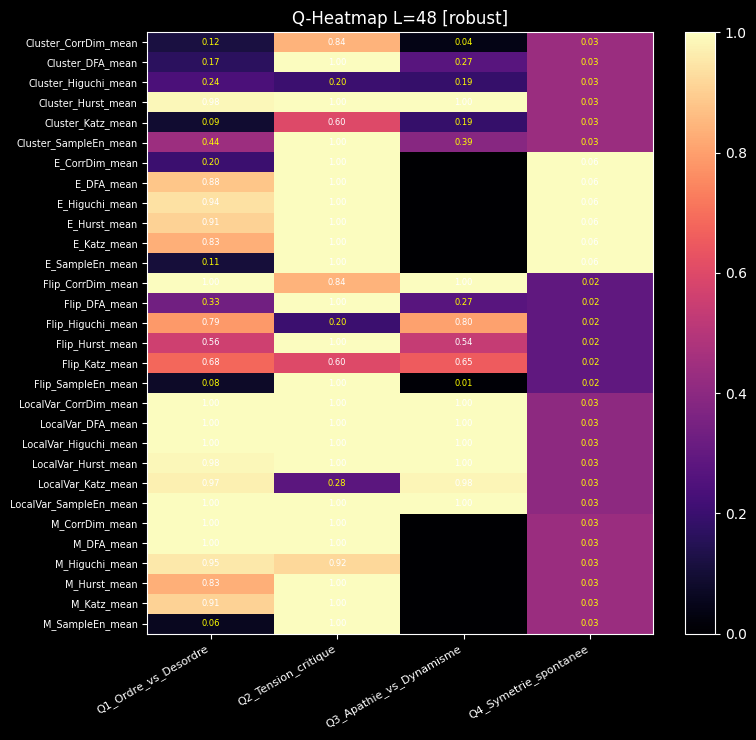


[OK] T_LOG v15.1 termine.


In [ ]:
# =============================================================================
# T_LOG v15.1 — Dual Mode : Fast (léger) vs Robust (complet)
# =============================================================================
# Mode FAST   : Cohen's d, 1 réalisation, Metropolis, seuils permissifs
# Mode ROBUST : Cliff + Mann-Whitney, Wolff + ensemble, bootstrap
# Basculez avec : MODE = 'fast'  ou  MODE = 'robust'
# =============================================================================

!pip install -q nolds antropy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.ndimage import label
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
import antropy, nolds

plt.style.use('dark_background')
TC_EXACT = 2.0 / np.log(1 + np.sqrt(2))

# ═══════════════════════════════════════════════════════════════════════════════
# CONFIGURATION GLOBALE — CHOIX DU MODE
# ═══════════════════════════════════════════════════════════════════════════════
MODE = 'robust'       # <-- 'fast' ou 'robust'

CONFIG = {
    'fast': {
        'n_realizations': 1,
        'steps': 8000,
        'transient_factor': 0.25,
        'algorithm': 'metropolis',      # toujours Metropolis
        'stat_test': 'cohen_d',         # Cohen's d simple
        'min_per_group': 2,             # seuil tres bas pour eviter NaN
        'estimator_min_len': 50,
        'cluster_interval': 50,
        'mann_whitney': False,
        'bootstrap': False,
    },
    'robust': {
        'n_realizations': 5,
        'steps': 40000,
        'transient_factor': 0.25,
        'algorithm': 'auto',            # Wolff pres de Tc, Metropolis ailleurs
        'stat_test': 'cliff_delta',     # Cliff's Delta + Mann-Whitney
        'min_per_group': 3,
        'estimator_min_len': 100,
        'cluster_interval': 50,
        'mann_whitney': True,
        'bootstrap': True,
    }
}
C = CONFIG[MODE]    # raccourci pratique

print(f"=== T_LOG v15.1 | MODE = {MODE.upper()} ===")
print(f"  Realisations : {C['n_realizations']} | Steps : {C['steps']} | "
      f"Test : {C['stat_test']} | Algo : {C['algorithm']}")


# ═══════════════════════════════════════════════════════════════════════════════
# 0. STATISTIQUES — Deux versions selon le mode
# ═══════════════════════════════════════════════════════════════════════════════

def cohen_d(group1, group2):
    """Cohen's d classique."""
    g1, g2 = np.asarray(group1), np.asarray(group2)
    n1, n2 = len(g1), len(g2)
    if n1 < 2 or n2 < 2:
        return np.nan
    pooled_std = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    if pooled_std < 1e-12:
        return 0.0
    return (np.mean(g1) - np.mean(g2)) / pooled_std


def cliff_delta(group1, group2):
    """Cliff's Delta robuste."""
    g1, g2 = np.asarray(group1), np.asarray(group2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']:
        return np.nan, np.nan
    # Mann-Whitney U -> Cliff's Delta
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        delta = (2 * U - n1 * n2) / (n1 * n2)
        return np.clip(delta, -1, 1), np.nan
    except Exception:
        return np.nan, np.nan


def separation_score(g1, g2):
    """Route vers le bon test selon le mode."""
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d, _ = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan


def mw_score(g1, g2):
    """Mann-Whitney -log10(p) optionnel (mode robust uniquement)."""
    if not C['mann_whitney']:
        return np.nan
    try:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return -np.log10(max(p, 1e-300))
    except Exception:
        return np.nan


# ═══════════════════════════════════════════════════════════════════════════════
# 1. SIMULATION — Metropolis CORRIGE + Wolff (mode robust)
# ═══════════════════════════════════════════════════════════════════════════════

def ising_metropolis(L, T, steps, transient, seed):
    """Metropolis checkerboard avec recalcul de nb a chaque parite."""
    rng = np.random.default_rng(seed)
    grid = rng.choice([-1., 1.], size=(L, L))
    M_h, E_h, flip_h, cluster_h, local_var_h = [], [], [], [], []

    for step in range(steps):
        flips = 0
        for parity in [0, 1]:
            # RECALCUL CRITIQUE des voisins a chaque sous-parite
            nb = (np.roll(grid, 1, 0) + np.roll(grid, -1, 0) +
                  np.roll(grid, 1, 1) + np.roll(grid, -1, 1))
            ii, jj = np.mgrid[0:L, 0:L]
            mask = ((ii + jj) % 2 == parity)
            dE = 2.0 * grid * nb
            acc = (dE <= 0) | (rng.random((L, L)) < np.exp(np.clip(-dE / T, -500, 0)))
            grid[mask & acc] *= -1
            flips += np.sum(acc & mask)

        if step >= transient:
            M = np.mean(grid)
            nb = (np.roll(grid, 1, 0) + np.roll(grid, -1, 0) +
                  np.roll(grid, 1, 1) + np.roll(grid, -1, 1))
            E = -0.5 * np.sum(grid * nb)
            M_h.append(M); E_h.append(E)
            flip_h.append(flips / (L * L))
            local_var_h.append(np.var(grid))
            if step % C['cluster_interval'] == 0:
                labeled, n = label(grid > 0)
                cluster_h.append(np.mean(np.bincount(labeled.ravel())[1:]**2) if n > 0 else 0)

    return {'M': np.array(M_h), 'E': np.array(E_h), 'Flip': np.array(flip_h),
            'Cluster': np.array(cluster_h) if cluster_h else np.array([0]),
            'LocalVar': np.array(local_var_h)}


def ising_wolff(L, T, steps, seed):
    """Wolff cluster-flip — uniquement mode robust pres de Tc."""
    rng = np.random.default_rng(seed)
    grid = rng.choice([-1., 1.], size=(L, L))
    p_add = 1.0 - np.exp(-2.0 / T) if T > 0 else 0.0
    M_h, E_h, cluster_h, local_var_h = [], [], [], []
    transient = steps // 4

    for step in range(steps):
        i, j = rng.integers(0, L, size=2)
        seed_spin = grid[i, j]
        grid[i, j] *= -1
        front, total = [(i, j)], 1
        while front:
            new_front = []
            for ci, cj in front:
                for di, dj in [(-1,0),(1,0),(0,-1),(0,1)]:
                    ni, nj = (ci+di)%L, (cj+dj)%L
                    if grid[ni, nj] == seed_spin and rng.random() < p_add:
                        grid[ni, nj] *= -1
                        new_front.append((ni, nj))
                        total += 1
            front = new_front

        if step >= transient:
            M_h.append(np.mean(grid))
            nb = (np.roll(grid,1,0)+np.roll(grid,-1,0)+np.roll(grid,1,1)+np.roll(grid,-1,1))
            E_h.append(-0.5 * np.sum(grid * nb))
            cluster_h.append(total)
            local_var_h.append(np.var(grid))

    return {'M': np.array(M_h), 'E': np.array(E_h),
            'Flip': np.array(cluster_h) / (L * L),
            'Cluster': np.array(cluster_h), 'LocalVar': np.array(local_var_h)}


def run_single_simulation(L, T, seed, steps=None):
    """Route vers le bon algorithme selon mode et temperature."""
    s = steps or C['steps']
    transient = int(s * C['transient_factor'])

    if C['algorithm'] == 'auto' and 0.8 * TC_EXACT <= T <= 1.3 * TC_EXACT:
        return ising_wolff(L, T, max(s // 5, 5000), seed)
    else:
        return ising_metropolis(L, T, s, transient, seed)


# ═══════════════════════════════════════════════════════════════════════════════
# 2. ESTIMATEURS
# ═══════════════════════════════════════════════════════════════════════════════

def apply_estimators(series, flux_name=''):
    """Estimateurs de complexite avec pre-traitement."""
    s = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi', 'DFA', 'Katz', 'CorrDim', 'Hurst', 'SampleEn']}

    # Pre-traitement : diff pour M/E, z-score pour tous
    if flux_name in ['M', 'E'] and np.std(s) > 1e-10:
        s = np.diff(s)
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi', 'DFA', 'Katz', 'CorrDim', 'Hurst', 'SampleEn']}

    est = {}
    safe = lambda f, x: f(x) if len(x) >= min_len else np.nan

    try: est['Higuchi'] = safe(antropy.higuchi_fd, s)
    except: est['Higuchi'] = np.nan
    try: est['DFA'] = 2.0 - safe(nolds.dfa, s)
    except: est['DFA'] = np.nan
    try: est['Katz'] = safe(antropy.katz_fd, s)
    except: est['Katz'] = np.nan
    try: est['CorrDim'] = nolds.corr_dim(s, emb_dim=3) if len(s) >= 500 else np.nan
    except: est['CorrDim'] = np.nan
    try: est['Hurst'] = safe(nolds.hurst_rs, s)
    except: est['Hurst'] = np.nan
    try: est['SampleEn'] = antropy.sample_entropy(s[:min(1000, len(s))], order=2)
    except: est['SampleEn'] = np.nan

    return est


# ═══════════════════════════════════════════════════════════════════════════════
# 3. PIPELINE — Simulations + Features
# ═══════════════════════════════════════════════════════════════════════════════

def build_features(L, T_values):
    """Lance les simulations et construit le DataFrame de features."""
    n = C['n_realizations']
    all_raw = []   # liste de dicts {T: fluxes} pour Q4

    print(f"\n[Build L={L}] {n} realisation(s), {C['steps']} steps, mode {MODE}")
    for rep in tqdm(range(n), desc=f"L={L} ensemble"):
        raw_by_T = {}
        for T in T_values:
            raw_by_T[T] = run_single_simulation(L, T, seed=1000*rep + int(T*100))
        all_raw.append(raw_by_T)

    # Agregation : moyenne +/- std sur realisations
    rows = []
    for T in T_values:
        row = {'T': T}
        for flux in ['M', 'E', 'Flip', 'Cluster', 'LocalVar']:
            # Collecter toutes les series de ce flux a cette T
            series_list = [raw[T][flux] for raw in all_raw]
            # Features sur chaque realisation
            feat_vals = {name: [] for name in ['Higuchi', 'DFA', 'Katz', 'CorrDim', 'Hurst', 'SampleEn']}
            for ser in series_list:
                ests = apply_estimators(ser, flux_name=flux)
                for k, v in ests.items():
                    if not np.isnan(v):
                        feat_vals[k].append(v)
            # Moyenne et std
            suffix = '_mean' if n > 1 else ''
            for k, vals in feat_vals.items():
                if vals:
                    row[f"{flux}_{k}{suffix}"] = np.mean(vals)
                    if n > 1:
                        row[f"{flux}_{k}_std"] = np.std(vals, ddof=1) if len(vals) > 1 else 0
                else:
                    row[f"{flux}_{k}{suffix}"] = np.nan
                    if n > 1:
                        row[f"{flux}_{k}_std"] = np.nan
        rows.append(row)

    df = pd.DataFrame(rows)
    feature_cols = [c for c in df.columns if c not in ['T'] and not c.endswith('_std')]
    return df, feature_cols, all_raw


# ═══════════════════════════════════════════════════════════════════════════════
# 4. LES 4 QUESTIONS
# ═══════════════════════════════════════════════════════════════════════════════

def compare_groups(df, feature_cols, t_low, t_high, label=""):
    """Compare deux plages de T et renvoie les scores de separation."""
    g_low = df[df['T'].between(t_low[0], t_low[1])]
    g_high = df[df['T'].between(t_high[0], t_high[1])]

    if len(g_low) < C['min_per_group'] or len(g_high) < C['min_per_group']:
        print(f"  [!] {label}: groupes trop petits ({len(g_low)}/{len(g_high)} pts)")

    scores = {}
    for col in feature_cols:
        if col not in df.columns:
            continue
        v1 = g_low[col].dropna().values
        v2 = g_high[col].dropna().values
        if len(v1) >= C['min_per_group'] and len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)


def run_four_questions(df, feature_cols, all_raw):
    """Calcule les 4 questions Ising."""
    print("\n=== 4 Questions ===")
    r = {}

    # Plages elargies au maximum pour eviter NaN
    print("Q1: Ordre vs Desordre...")
    r["Q1_Ordre_vs_Desordre"] = compare_groups(
        df, feature_cols, [1.5, 2.15], [2.35, 3.5], "Q1")

    print("Q2: Tension critique...")
    r["Q2_Tension_critique"] = compare_groups(
        df, feature_cols, [2.0, 2.25], [2.30, 2.55], "Q2")

    print("Q3: Apathie vs Dynamisme...")
    dyn_cols = [c for c in feature_cols if any(x in c for x in ['Flip', 'LocalVar', 'Cluster'])]
    r["Q3_Apathie_vs_Dynamisme"] = compare_groups(
        df, dyn_cols, [1.5, 2.1], [2.35, 3.5], "Q3")

    # Q4 : Symetrie spontanee (retournements intra-simulation)
    print("Q4: Symetrie spontanee...")
    q4 = {}
    for col in feature_cols:
        flux = col.split('_')[0]
        effects = []
        for raw_by_T in all_raw:
            for T, fluxes in raw_by_T.items():
                if flux not in fluxes:
                    continue
                s = fluxes[flux]
                if len(s) < 100:
                    continue
                mid = len(s) // 2
                d = cohen_d(s[:mid], s[mid:]) if C['stat_test'] == 'cohen_d' \
                    else separation_score(s[:mid], s[mid:])
                if not np.isnan(d):
                    effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Symetrie_spontanee"] = pd.Series(q4)

    summary = pd.DataFrame({k: v.round(3) for k, v in r.items()})
    return summary, r


# ═══════════════════════════════════════════════════════════════════════════════
# 5. VISUALISATION
# ═══════════════════════════════════════════════════════════════════════════════

def plot_landscape(df, L):
    """Affiche l'evolution des features principales."""
    mean_cols = [c for c in df.columns if c.endswith('_mean')]
    cols = mean_cols if mean_cols else [c for c in df.columns if c != 'T' and not c.endswith('_std')]
    n = min(len(cols), 12)
    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    axes = axes.flatten()

    for i, col in enumerate(cols[:n]):
        ax = axes[i]
        ax.plot(df['T'], df[col], 'o-', color='cyan', markersize=3)
        std_col = col.replace('_mean', '_std')
        if std_col in df.columns:
            ax.fill_between(df['T'], df[col] - df[std_col], df[col] + df[std_col],
                           alpha=0.25, color='cyan')
        ax.axvline(TC_EXACT, color='r', linestyle='--', alpha=0.6)
        ax.set_title(col.replace('_mean', ''), fontsize=8)
        ax.set_xlabel('T'); ax.grid(True, alpha=0.2)

    plt.suptitle(f"T_LOG v15.1 [{MODE}] — L={L}", fontsize=11)
    plt.tight_layout(); plt.show()


def plot_heatmap(summary, L):
    """Heatmap des scores des 4 questions."""
    fig, ax = plt.subplots(figsize=(8, max(4, len(summary)*0.25)))
    data = summary.fillna(0).copy()
    for c in data.columns:
        m = data[c].max()
        if m > 0: data[c] /= m
    im = ax.imshow(data.values, aspect='auto', cmap='magma')
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=30, ha='right', fontsize=8)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels(data.index, fontsize=7)
    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = summary.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha='center', va='center',
                       color='w' if data.iloc[i, j] > 0.5 else 'yellow', fontsize=6)
    plt.colorbar(im, ax=ax); plt.title(f"Q-Heatmap L={L} [{MODE}]")
    plt.tight_layout(); plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# 6. EXECUTION PRINCIPALE
# ═══════════════════════════════════════════════════════════════════════════════

def main():
    # Grille de temperature : fine autour de Tc, eparse ailleurs
    T_SCAN = np.round(np.concatenate([
        np.arange(1.5, 2.15, 0.06),
        np.arange(2.15, 2.35, 0.035),   # tres fine pres de Tc
        np.arange(2.35, 3.0, 0.06)
    ]), 3)
    SIZES = [32, 48]

    print(f"\nPoints T : {len(T_SCAN)} | Tc = {TC_EXACT:.4f}")
    print("=" * 60)

    for L in SIZES:
        print(f"\n{'='*40}\n>>> L = {L}\n{'='*40}")

        # Simulations + features
        df, feature_cols, all_raw = build_features(L, T_SCAN)
        print(f"Features : {len(feature_cols)}")
        print(df[['T'] + feature_cols[:4]].head(3).to_string())

        # Landscape
        plot_landscape(df, L)

        # 4 Questions
        summary, results = run_four_questions(df, feature_cols, all_raw)
        print(f"\n>>> RESULTATS L={L}:")
        print(summary.to_string())

        # Top features par question
        print(f"\n>>> TOP 3 PAR QUESTION L={L}:")
        for q in summary.columns:
            top = summary[q].dropna().sort_values(ascending=False).head(3)
            if len(top):
                print(f"  [{q}]")
                for f, v in top.items():
                    print(f"    {f:35s} : {v:.3f}")

        plot_heatmap(summary, L)

    print("\n[OK] T_LOG v15.1 termine.")


if __name__ == "__main__":
    main()